# NYC Housing Construction Activity and Street Safety
**Data Engineering and Visualization, Project Milestone 1**

Research question: do ZIP codes with more construction and renovation permit activity also have more street-safety problems (crashes and injuries)?

| Dataset | Source |
|---|---|
| Housing and Development: DOB NOW: Build, Approved Permits (`rbx6-tga4`) | NYC Open Data |
| Transportation: Motor Vehicle Collisions, Crashes (`h9gi-nx95`) | NYC Open Data |

**How to run this notebook**
1. Run the Setup cell, then use *Runtime > Run all*. The first run downloads the data (a few minutes). Later runs reuse the copies saved in Google Drive.
2. If Colab restarts or disconnects partway through, set `RESTART_FROM_DRIVE = True` in the Setup cell, run Setup, then run from section 7 onward.
3. Everything is saved to the `DEV_Project` folder in Google Drive.

## 0. Setup

**About the saved outputs.** Section 7 (research questions and charts) was run on the final table `integrated_clean.csv`, and its results are saved in this notebook so they can be read without re-running. The charts are saved as static images; run the cells to get the interactive versions. The Q4 image has no street background because the tool that exported it could not load map tiles; running the cell draws the street map. Apart from the two download steps in section 2, sections 2 to 6 (loading, exploration, cleaning, integration) have no saved outputs. Their numbers in the text come from the original runs, and the cells regenerate them when run from the top.

In [ ]:
import os
import pandas as pd
import numpy as np
import plotly.express as px
from google.colab import drive

drive.mount('/content/drive')          # a popup appears: click Connect, then Allow
D = '/content/drive/MyDrive/DEV_Project/'
os.makedirs(D, exist_ok=True)

# Set to True ONLY after a Colab restart: reloads the saved cleaned data and lets you jump to section 7
RESTART_FROM_DRIVE = False
print('pandas', pd.__version__)

In [ ]:
# Restart point (does nothing unless RESTART_FROM_DRIVE = True)
if RESTART_FROM_DRIVE:
    hc = pd.read_csv(D + 'housing_clean.csv', dtype={'zip_code': str},
                     parse_dates=['issued_date', 'approved_date', 'year_month'])
    tc = pd.read_csv(D + 'transport_clean.csv', dtype={'zip_code': str},
                     parse_dates=['crash_date', 'year_month'])
    m = pd.read_csv(D + 'integrated_clean.csv', dtype={'zip_code': str}, parse_dates=['year_month'])
    print('housing:', hc.shape, '| transport:', tc.shape, '| integrated:', m.shape)
else:
    print('Normal run: nothing to reload.')

## 1. Dataset Overview and Selection Reasoning

### Chosen datasets
- Housing & Development: DOB NOW: Build – Approved Permits (rbx6-tga4) — about 1.03 million rows, 46 columns (each row is a permit issued through DOB NOW since 2016)
- Transportation: Motor Vehicle Collisions – Crashes (h9gi-nx95) — about 2.3 million rows, 29 columns (each row is one collision)
- Links: https://data.cityofnewyork.us/d/rbx6-tga4 and https://data.cityofnewyork.us/d/h9gi-nx95

### Why these
Both datasets record borough, ZIP code, and a date, so they can be aggregated to a shared
ZIP code x month level and joined there. We do not join row to row, because a permit and
a crash are different kinds of event.
- Housing bridge columns: Borough, Zip Code, Issued Date (also Approved Date, Latitude, Longitude)
- Transport bridge columns: BOROUGH, ZIP CODE, CRASH DATE (also LATITUDE, LONGITUDE)

**Question:** do areas with more construction and renovation permit activity also have more
street-safety problems (crashes and injuries)?

### Scale and sampling
The full datasets (about 1.03M x 46 and 2.3M x 29) are large enough to crash a Colab notebook.
We download a filtered sample instead: 1 January 2023 to 31 December 2025.
- Three full calendar years avoid the distortion of a partial year, and 2026 is excluded
  because it is incomplete and recent records lag.
- Recent years reflect current conditions, after the 2020-2021 pandemic disruption.
- Only the columns we need are downloaded, in chunks of 50,000 rows.
- Resulting samples: 484,454 permits and 273,483 crashes.

### Known issues (to confirm in EDA)
- Housing: permits cover all work types, not only residential construction; some rows
  may lack ZIP or coordinates.
- Transport: crash ZIP, borough and coordinates are often missing; many columns are sparse.
- Permits measure planned work, not people moving in, so the link to crashes is correlational only.

## 2. Loading the Data

### 2.1 Verifying API field names and date types
Before filtering, we confirm the exact API field names and that the date columns are real dates, so a date filter cannot silently return the wrong rows.

In [ ]:
import requests, time

def get_json(url, params=None, tries=4):
    """GET a NYC Open Data URL and return parsed JSON, retrying if the server is busy."""
    for attempt in range(1, tries + 1):
        r = requests.get(url, params=params,
                         headers={'User-Agent': 'Mozilla/5.0'}, timeout=60)
        if r.status_code == 200:
            return r.json()
        print('status', r.status_code, '- retrying')
        time.sleep(8)
    return None

# Fields we plan to use (API names, lowercase with underscores)
needed = {
    'rbx6-tga4': ['issued_date', 'approved_date', 'borough', 'zip_code', 'work_type',
                  'latitude', 'longitude', 'estimated_job_costs', 'permit_status',
                  'job_filing_number', 'work_permit'],
    'h9gi-nx95': ['crash_date', 'borough', 'zip_code', 'latitude', 'longitude',
                  'number_of_persons_injured', 'number_of_persons_killed',
                  'number_of_pedestrians_injured', 'number_of_cyclist_injured',
                  'number_of_motorist_injured', 'contributing_factor_vehicle_1',
                  'collision_id'],
}
date_field = {'rbx6-tga4': 'issued_date', 'h9gi-nx95': 'crash_date'}

for ds, wanted in needed.items():
    cols = get_json(f'https://data.cityofnewyork.us/api/views/{ds}/columns.json')
    if cols is None:
        print(ds, 'could not fetch columns, rerun in a minute')
        continue
    types = {c['fieldName']: c['dataTypeName'] for c in cols}
    print(ds, '| MISSING field names:', [f for f in wanted if f not in types])
    print(ds, '| date field type:', types.get(date_field[ds]))
    print(ds, '| all field names:', list(types))
    rows = get_json(f'https://data.cityofnewyork.us/resource/{ds}.json',
                    {'$select': date_field[ds], '$limit': 3})
    print(ds, '| sample date values:', rows)
    print('-' * 60)

rbx6-tga4 | MISSING field names: []
rbx6-tga4 | date field type: calendar_date
rbx6-tga4 | all field names: ['job_filing_number', 'work_permit', 'sequence_number', 'filing_reason', 'house_no', 'street_name', 'borough', 'lot', 'bin', 'block', 'c_b_no', 'apt_condo_no_s', 'work_on_floor', 'work_type', 'permittee_s_license_type', 'applicant_license', 'applicant_first_name', 'applicant_middle_name', 'applicant_last_name', 'applicant_business_name', 'applicant_business_address', 'filing_representative_first_name', 'filing_representative_middle_initial', 'filing_representative_last_name', 'filing_representative_business_name', 'approved_date', 'issued_date', 'expired_date', 'job_description', 'estimated_job_costs', 'owner_business_name', 'owner_name', 'owner_street_address', 'owner_city', 'owner_state', 'owner_zip_code', 'permit_status', 'tracking_number', 'zip_code', 'latitude', 'longitude', 'community_board', 'council_district', 'bbl', 'census_tract', 'nta']
status 503 - retrying
rbx6-tga4 

### 2.2 Loading approach and download
Full datasets are too large for Colab, so we use SoQL filters through the API (as in the
project description, Listing 2). We filter on the date column (issued_date / crash_date) to
1 Jan 2023 - 31 Dec 2025 and select only the columns needed. Rows are downloaded in pages of
50,000 and saved to CSV to avoid re-downloading. Housing rows without an issued_date are
excluded by the filter and are discussed in the cleaning section.

In [ ]:
import io, os, time
import requests
import pandas as pd

BASE = 'https://data.cityofnewyork.us/resource/{}.csv'
HEADERS = {'User-Agent': 'Mozilla/5.0'}

def count_rows(dataset_id, where):
    """Ask the API how many rows match the filter, so we know the download size."""
    r = requests.get(BASE.format(dataset_id),
                     params={'$select': 'count(*)', '$where': where},
                     headers=HEADERS, timeout=120)
    r.raise_for_status()
    return int(pd.read_csv(io.StringIO(r.text)).iloc[0, 0])

def download_filtered(dataset_id, columns, where, out_path, page_size=50000, tries=5):
    """Download rows matching `where` page by page (keeps Colab memory safe).
    Retries on 503 (server busy). Saves to CSV so a runtime reset doesn't lose work."""
    if os.path.exists(out_path):
        print('Found saved file, loading it:', out_path)
        return pd.read_csv(out_path, low_memory=False, dtype={'zip_code': str})

    total = count_rows(dataset_id, where)
    print(f'{dataset_id}: {total:,} rows match the filter')

    pages = []
    for offset in range(0, total, page_size):
        params = {'$select': ','.join(columns), '$where': where,
                  '$order': ':id',                  # stable order so paging is repeatable
                  '$limit': page_size, '$offset': offset}
        for attempt in range(1, tries + 1):
            r = requests.get(BASE.format(dataset_id), params=params,
                             headers=HEADERS, timeout=180)
            if r.status_code == 200:
                break
            print(f'  status {r.status_code} at offset {offset}, retry {attempt}')
            time.sleep(10)
        else:
            raise RuntimeError(f'Failed at offset {offset}; rerun the cell')
        pages.append(pd.read_csv(io.StringIO(r.text), low_memory=False,
                                 dtype={'zip_code': str}))   # keep ZIP as text
        print(f'  downloaded {offset + len(pages[-1]):,} / {total:,}')

    df = pd.concat(pages, ignore_index=True)
    df.to_csv(out_path, index=False)
    return df

# Sample window: 1 Jan 2023 to 31 Dec 2025 (justified in sections 1 and 2)
START, END = '2023-01-01T00:00:00', '2026-01-01T00:00:00'

housing_cols = ['job_filing_number', 'work_permit', 'borough', 'zip_code', 'work_type',
                'permit_status', 'issued_date', 'approved_date', 'estimated_job_costs',
                'latitude', 'longitude', 'community_board', 'nta', 'block', 'lot',
                'filing_reason']
transport_cols = ['collision_id', 'crash_date', 'crash_time', 'borough', 'zip_code',
                  'latitude', 'longitude', 'on_street_name',
                  'number_of_persons_injured', 'number_of_persons_killed',
                  'number_of_pedestrians_injured', 'number_of_pedestrians_killed',
                  'number_of_cyclist_injured', 'number_of_cyclist_killed',
                  'number_of_motorist_injured', 'number_of_motorist_killed',
                  'contributing_factor_vehicle_1', 'vehicle_type_code1']

df_housing = download_filtered(
    'rbx6-tga4', housing_cols,
    f"issued_date >= '{START}' AND issued_date < '{END}'",
    D + 'housing_raw.csv')

df_transport = download_filtered(
    'h9gi-nx95', transport_cols,
    f"crash_date >= '{START}' AND crash_date < '{END}'",
    D + 'transport_raw.csv')

# Quick sanity summary
for name, df, date_col in [('HOUSING', df_housing, 'issued_date'),
                           ('TRANSPORT', df_transport, 'crash_date')]:
    print('\n' + name, df.shape)
    print('date range:', df[date_col].min(), 'to', df[date_col].max())
    print(df.isna().sum().sort_values(ascending=False).head(6))

rbx6-tga4: 484,454 rows match the filter
  downloaded 50,000 / 484,454
  status 503 at offset 50000, retry 1
  status 503 at offset 50000, retry 2
  downloaded 100,000 / 484,454
  downloaded 150,000 / 484,454
  status 503 at offset 150000, retry 1
  status 503 at offset 150000, retry 2
  status 503 at offset 150000, retry 3
  status 500 at offset 150000, retry 4
  downloaded 200,000 / 484,454
  downloaded 250,000 / 484,454
  status 500 at offset 250000, retry 1
  downloaded 300,000 / 484,454
  downloaded 350,000 / 484,454
  downloaded 400,000 / 484,454
  downloaded 450,000 / 484,454
  downloaded 484,454 / 484,454
h9gi-nx95: 273,483 rows match the filter
  downloaded 50,000 / 273,483
  downloaded 100,000 / 273,483
  status 503 at offset 100000, retry 1
  downloaded 150,000 / 273,483
  status 503 at offset 150000, retry 1
  downloaded 200,000 / 273,483
  status 503 at offset 200000, retry 1
  downloaded 250,000 / 273,483
  downloaded 273,483 / 273,483

HOUSING (484454, 16)
date range: 20

## 3. Exploratory Data Analysis (EDA)

### 3.1 Structure and quality

In [ ]:
import pandas as pd
import numpy as np
import plotly.express as px

# Work on copies so the raw downloads stay untouched (formal cleaning is section 4)
h = df_housing.copy()
t = df_transport.copy()
h['issued_date'] = pd.to_datetime(h['issued_date'], errors='coerce')
t['crash_date'] = pd.to_datetime(t['crash_date'], errors='coerce')
h['estimated_job_costs'] = pd.to_numeric(h['estimated_job_costs'], errors='coerce')

def missing_table(df):
    """Missing count and percentage per column, worst first."""
    m = df.isna().sum().to_frame('missing')
    m['pct'] = (m['missing'] / len(df) * 100).round(2)
    return m.sort_values('pct', ascending=False)

print('HOUSING dtypes:\n', df_housing.dtypes, '\n')
print('HOUSING missing:\n', missing_table(df_housing).head(8), '\n')
print('TRANSPORT dtypes:\n', df_transport.dtypes, '\n')
print('TRANSPORT missing:\n', missing_table(df_transport).head(8), '\n')

# Duplicates: exact duplicate rows, and duplicates of the ID columns
print('HOUSING exact duplicate rows:', df_housing.duplicated().sum())
print('HOUSING duplicate (job_filing_number, work_permit):',
      df_housing.duplicated(['job_filing_number', 'work_permit']).sum())
print('TRANSPORT exact duplicate rows:', df_transport.duplicated().sum())
print('TRANSPORT duplicate collision_id:', df_transport['collision_id'].duplicated().sum())

# Join-key compatibility: borough spelling and ZIP format must match across datasets
print('\nHousing boroughs:', sorted(df_housing['borough'].dropna().unique()))
print('Transport boroughs:', sorted(df_transport['borough'].dropna().unique()))
print('Housing ZIP lengths:', df_housing['zip_code'].dropna().str.len().value_counts().to_dict())
print('Transport ZIP lengths:', df_transport['zip_code'].dropna().str.len().value_counts().to_dict())

### 3.2 Descriptive statistics

In [ ]:
print('HOUSING estimated_job_costs:\n', h['estimated_job_costs'].describe().round(0))
print('\nHOUSING permits by work_type:\n', h['work_type'].value_counts())
print('\nHOUSING permits by permit_status:\n', h['permit_status'].value_counts())

injury_cols = [c for c in t.columns if c.startswith('number_of_')]
print('\nTRANSPORT injury/death columns:\n', t[injury_cols].describe().round(2).T)
print('\nTRANSPORT top contributing factors:\n',
      t['contributing_factor_vehicle_1'].value_counts().head(8))

### 3.3 Visual exploration

In [ ]:
# 1. Permits per month
perm_m = h.dropna(subset=['issued_date']).set_index('issued_date').resample('MS').size().reset_index(name='permits')
px.line(perm_m, x='issued_date', y='permits', markers=True,
        title='Approved DOB NOW permits per month (2023-2025)',
        labels={'issued_date': 'Month', 'permits': 'Number of permits'}).show()

# 2. Crashes per month
crash_m = t.dropna(subset=['crash_date']).set_index('crash_date').resample('MS').size().reset_index(name='crashes')
px.line(crash_m, x='crash_date', y='crashes', markers=True,
        title='Motor vehicle collisions per month (2023-2025)',
        labels={'crash_date': 'Month', 'crashes': 'Number of crashes'}).show()

# 3. Permits by borough
hb = h['borough'].fillna('MISSING').value_counts().reset_index()
hb.columns = ['borough', 'permits']
px.bar(hb, x='borough', y='permits', title='Permits by borough',
       labels={'borough': 'Borough', 'permits': 'Number of permits'}).show()

# 4. Crashes by borough (missing shown explicitly)
tb = t['borough'].fillna('MISSING').value_counts().reset_index()
tb.columns = ['borough', 'crashes']
px.bar(tb, x='borough', y='crashes', title='Crashes by borough (MISSING = no borough recorded)',
       labels={'borough': 'Borough', 'crashes': 'Number of crashes'}).show()

# 5. Permit cost distribution (log scale because costs are extremely skewed)
costs = h.loc[h['estimated_job_costs'] > 0, 'estimated_job_costs']
px.histogram(np.log10(costs), nbins=50, title='Permit estimated cost, log10 scale (zero costs excluded)',
             labels={'value': 'log10(estimated job cost in $)', 'count': 'Permits'}).show()

# 6. Permits by work type
hw = h['work_type'].fillna('MISSING').value_counts().reset_index()
hw.columns = ['work_type', 'permits']
px.bar(hw, x='work_type', y='permits', title='Permits by work type',
       labels={'work_type': 'Work type', 'permits': 'Number of permits'}).show()

### 3.4 EDA findings
**Housing (484,454 permits issued 2023-2025).** Key fields are nearly complete: borough 0%
missing, ZIP 0.13%, coordinates 0.47%. There are 622 exact duplicate rows (640 after borough case is standardized, see 4.1). Borough uses mixed
case (BRONX vs Bronx). Estimated cost is heavily skewed (median $25,584, mean $323,940, max
$800,010,000) with a cluster of near-zero placeholder values. The 21 work types include many
that are not about buildings (Sidewalk Shed, Construction Fence, Sign), so they need grouping.
Permits per month are stable (about 11.5k-15.5k) with no gaps.

**Transport (273,483 crashes 2023-2025).** No duplicate rows or collision IDs. Borough (23.4%),
ZIP (27.0%) and coordinates (5.5%) have substantial missing values; most missing ZIP/borough
rows still have coordinates, so they can be recovered. Most crashes injure nobody (median 0);
deaths are rare. About a third of contributing factors are "Unspecified" or "Does Not Apply".
Monthly crashes decline from about 9,000 (May 2023) to about 7,500 in 2025, with a low near
6,000 in February 2025; the data does not explain why, so we describe the trend without
claiming a cause.

### 3.5 Pre-cleaning diagnostics

In [ ]:
# --- 1. What makes the housing "duplicates"? Which columns differ inside a repeated group? ---
key = ['job_filing_number', 'work_permit']
dup_groups = h[h.duplicated(key, keep=False) & h['work_permit'].notna()]
print('rows in repeated groups:', len(dup_groups), '| groups:', dup_groups.groupby(key).ngroups)
differs = dup_groups.groupby(key).nunique(dropna=False).gt(1).mean() * 100
print('\n% of groups where each column has more than one distinct value:')
print(differs.round(1).sort_values(ascending=False))
print('\nExample group:')
print(dup_groups.sort_values(key).head(4).T)

# --- 2. Placeholder and extreme permit costs ---
c = h['estimated_job_costs']
print('\ncost == 0:', (c == 0).sum(), '| cost 0-100 (excl. 0):', c.between(0.0001, 99.99).sum(),
      '| cost == 1:', (c == 1).sum(), '| cost > $100M:', (c > 1e8).sum())
print(h.nlargest(5, 'estimated_job_costs')[['work_type', 'estimated_job_costs', 'borough', 'issued_date']])

# --- 3. ZIP codes that are not NYC ZIPs (valid NYC ZIP prefixes below) ---
nyc_prefixes = ['100', '101', '102', '103', '104', '110', '111', '112', '113', '114', '116']
for name, df in [('Housing', h), ('Transport', t)]:
    z = df['zip_code'].dropna()
    bad = z[~z.str[:3].isin(nyc_prefixes)]
    print(f'\n{name} ZIPs outside NYC prefixes: {len(bad)}', bad.value_counts().head(5).to_dict())

# --- 4. Coordinates outside NYC, including (0, 0) placeholders ---
def outside_nyc(df):
    ll = df.dropna(subset=['latitude', 'longitude'])
    return ~ll['latitude'].between(40.45, 40.95) | ~ll['longitude'].between(-74.30, -73.65)
print('\nHousing coordinates outside NYC box:', outside_nyc(h).sum())
print('Transport coordinates outside NYC box:', outside_nyc(t).sum())

# --- 5. Do the injury columns add up, and how recoverable are the missing ZIP/borough rows? ---
parts = t[['number_of_pedestrians_injured', 'number_of_cyclist_injured',
           'number_of_motorist_injured']].sum(axis=1)
print('\npersons_injured != pedestrian+cyclist+motorist:', (t['number_of_persons_injured'] != parts).sum())
print('Crashes missing borough but with coordinates:', (t['borough'].isna() & t['latitude'].notna()).sum())
print('Crashes missing ZIP but with coordinates:', (t['zip_code'].isna() & t['latitude'].notna()).sum())

## 4. Pre-Integration Cleaning

### 4.0 Cleaning decisions and justification
**Housing**
- Duplicates: 640 exact duplicate rows are dropped. 168,898 further rows repeat a (job_filing_number,
  work_permit) pair but differ in issued_date/filing_reason (renewals), so they are kept: each renewal
  is a separate issuance. Dropping them would hide real activity.
- Borough standardized to upper case before de-duplicating (BRONX vs Bronx).
- Cost: values below $100 (0, 1 and other placeholders) are set to missing, not imputed, because
  there is no reliable way to estimate a job cost. Values above $100M (93 rows) are treated as probable
  entry errors and set to missing. Detected with an IQR fence on log10(cost) plus a domain rule.
  Permits are never dropped for cost, since the permit still counts as activity.
  Costs appear to be job-level and repeat across a job's permits, so we use medians, never sums.
- ZIP: rows with a missing or non-NYC ZIP (e.g. 10803) are dropped (about 0.13%); ZIP is our join key.
- Work types (21) are grouped into 4 groups to keep dashboard filters usable.
- Coordinates (0.47% missing) are left missing: they are only needed for maps, not for the join.

**Transport**
- Missing ZIP (27%) and borough (23%) are recovered from coordinates with a nearest-neighbour lookup
  (validated on held-out data, accuracy reported below). Borough is then taken from the ZIP.
  Rows that cannot be recovered are dropped because the join needs a ZIP.
- Coordinates outside the NYC bounding box (2,752 rows, includes placeholder values) are set to missing.
- The invalid ZIP 12345 is set to missing, then recovered like the others.
- Injury/death counts are real events, so large values are kept (domain rule); an IQR rule would
  wrongly flag most injury crashes. Rows where persons_injured does not equal the sum of its parts
  are flagged, not dropped.
- "Does Not Apply", "Unspecified" and missing contributing factors are merged into "Unspecified".

### 4.1 Housing cleaning

In [ ]:
import numpy as np
import pandas as pd

NYC_ZIP_PREFIXES = ['100', '101', '102', '103', '104', '110', '111', '112', '113', '114', '116']

hc = df_housing.copy()          # always start from the raw download
log = {'start_rows': len(hc)}

# --- Standardize formats ---
hc['borough'] = hc['borough'].str.strip().str.upper()
hc['zip_code'] = hc['zip_code'].str.strip()
for col in ['issued_date', 'approved_date']:
    hc[col] = pd.to_datetime(hc[col], errors='coerce')
hc['estimated_job_costs'] = pd.to_numeric(hc['estimated_job_costs'], errors='coerce')
hc['work_type'] = hc['work_type'].str.strip()

# --- Rows with no permit ID cannot be traced or de-duplicated ---
n = len(hc); hc = hc.dropna(subset=['job_filing_number', 'work_permit'])
log['dropped_no_permit_id'] = n - len(hc)

# --- Exact duplicates (after standardizing, so BRONX/Bronx copies are caught) ---
n = len(hc); hc = hc.drop_duplicates()
log['dropped_exact_duplicates'] = n - len(hc)

# --- ZIP is the join key: drop missing or non-NYC ZIPs ---
valid_zip = hc['zip_code'].str[:3].isin(NYC_ZIP_PREFIXES)
log['dropped_missing_or_non_nyc_zip'] = int((~valid_zip).sum())
hc = hc[valid_zip].copy()

# --- Cost outliers: detect with IQR on log10, address with domain rules ---
cost = hc['estimated_job_costs']
lg = np.log10(cost[cost >= 100])
q1, q3 = lg.quantile([0.25, 0.75]); iqr = q3 - q1
lower_fence, upper_fence = 10 ** (q1 - 1.5 * iqr), 10 ** (q3 + 1.5 * iqr)
print(f'IQR fences on cost: ${lower_fence:,.0f} to ${upper_fence:,.0f}')
hc['cost_iqr_flag'] = (cost > upper_fence) | ((cost >= 100) & (cost < lower_fence))
log['cost_iqr_flagged_kept'] = int(hc['cost_iqr_flag'].sum())

hc['cost_clean'] = cost.where(cost >= 100)                  # placeholders -> missing
log['placeholder_costs_set_missing'] = int((cost < 100).sum())
log['extreme_costs_over_100M_set_missing'] = int((cost > 1e8).sum())
hc.loc[hc['cost_clean'] > 1e8, 'cost_clean'] = np.nan       # probable entry errors

# --- Group the 21 work types ---
WORK_GROUPS = {
    'Construction & structural': ['General Construction', 'Structural', 'Foundation', 'Earth Work',
                                  'Support of Excavation', 'Full Demolition'],
    'Building systems & equipment': ['Plumbing', 'Mechanical Systems', 'Sprinklers', 'Standpipe',
                                     'Boiler Equipment', 'Solar', 'Antenna', 'Green Roof'],
    'Site safety & temporary': ['Sidewalk Shed', 'Construction Fence', 'Supported Scaffold',
                                'Suspended Scaffold', 'Protection and Mechanical Methods'],
    'Other': ['Sign', 'Curb Cut'],
}
type_to_group = {wt: g for g, types in WORK_GROUPS.items() for wt in types}
hc['work_group'] = hc['work_type'].map(type_to_group)
assert hc['work_group'].notna().all(), hc.loc[hc['work_group'].isna(), 'work_type'].unique()

# --- Time columns for the join ---
hc['year'] = hc['issued_date'].dt.year
hc['month'] = hc['issued_date'].dt.month
hc['year_month'] = hc['issued_date'].dt.to_period('M').dt.to_timestamp()

log['final_rows'] = len(hc)
print(pd.Series(log))
print('\nMissing after cleaning:\n', hc.isna().sum()[lambda s: s > 0])
print('\nBoroughs:', sorted(hc['borough'].unique()))
print(hc['work_group'].value_counts())
hc.to_csv('/content/housing_clean.csv', index=False)

### 4.2 Transport cleaning

In [ ]:
tc = df_transport.copy()
tlog = {'start_rows': len(tc)}

# --- Standardize formats ---
tc['crash_date'] = pd.to_datetime(tc['crash_date'], errors='coerce')
tc['year'] = tc['crash_date'].dt.year
tc['month'] = tc['crash_date'].dt.month
tc['year_month'] = tc['crash_date'].dt.to_period('M').dt.to_timestamp()
tc['crash_hour'] = pd.to_numeric(tc['crash_time'].str.split(':').str[0], errors='coerce')
tc['borough'] = tc['borough'].str.strip().str.upper()
tc['zip_code'] = tc['zip_code'].str.strip()
tc['on_street_name'] = tc['on_street_name'].str.strip().str.upper()

# --- Invalid ZIPs (non-NYC, e.g. 12345) -> missing ---
bad_zip = tc['zip_code'].notna() & ~tc['zip_code'].str[:3].isin(NYC_ZIP_PREFIXES)
tlog['invalid_zip_set_missing'] = int(bad_zip.sum())
tc.loc[bad_zip, 'zip_code'] = np.nan

# --- Coordinates outside the NYC box (incl. 0,0 placeholders) -> missing ---
ll = tc['latitude'].notna() & tc['longitude'].notna()
outside = ll & (~tc['latitude'].between(40.45, 40.95) | ~tc['longitude'].between(-74.30, -73.65))
tlog['bad_coordinates_set_missing'] = int(outside.sum())
tc.loc[outside, ['latitude', 'longitude']] = np.nan

# --- Injury consistency: flag, do not drop ---
inj_parts = tc[['number_of_pedestrians_injured', 'number_of_cyclist_injured',
                'number_of_motorist_injured']].sum(axis=1)
diff = tc['number_of_persons_injured'] - inj_parts
tc['injury_mismatch'] = diff != 0
print('persons_injured > sum of parts:', int((diff > 0).sum()), '| < sum of parts:', int((diff < 0).sum()))
kill_parts = tc[['number_of_pedestrians_killed', 'number_of_cyclist_killed',
                 'number_of_motorist_killed']].sum(axis=1)
print('killed mismatches:', int((tc['number_of_persons_killed'] != kill_parts).sum()))

# --- Categories ---
tc['contributing_factor_vehicle_1'] = (tc['contributing_factor_vehicle_1'].fillna('Unspecified')
                                       .str.strip().replace({'Does Not Apply': 'Unspecified'}))
tc['vehicle_type_code1'] = tc['vehicle_type_code1'].str.strip().str.upper().fillna('UNKNOWN')

print(pd.Series(tlog))
print('\nstill missing ZIP:', int(tc['zip_code'].isna().sum()),
      '| missing borough:', int(tc['borough'].isna().sum()),
      '| missing coordinates:', int(tc['latitude'].isna().sum()))

### 4.3 Recovering ZIP and borough from coordinates

In [ ]:
from sklearn.neighbors import BallTree

EARTH_M = 6_371_000
MAX_DISTANCE_M = 300     # do not assign a ZIP if the nearest known crash is farther than this

def rad(df):
    """Latitude/longitude in radians, as the haversine tree expects."""
    return np.radians(df[['latitude', 'longitude']].to_numpy())

known = tc[tc['zip_code'].notna() & tc['latitude'].notna()]
unknown = tc[tc['zip_code'].isna() & tc['latitude'].notna()]

# --- Validation: hide 20% of the known ZIPs and see how often we predict them correctly ---
rng = np.random.default_rng(42)
is_train = rng.random(len(known)) < 0.8
train, test = known[is_train], known[~is_train]
tree = BallTree(rad(train), metric='haversine')
dist, idx = tree.query(rad(test), k=1)
dist_m = dist[:, 0] * EARTH_M
pred = train['zip_code'].to_numpy()[idx[:, 0]]
hit = pred == test['zip_code'].to_numpy()
near = dist_m <= MAX_DISTANCE_M
print(f'Validation accuracy (all): {hit.mean():.3%}')
print(f'Validation accuracy (within {MAX_DISTANCE_M} m): {hit[near].mean():.3%} on {near.mean():.1%} of test rows')

# --- Apply to the real missing-ZIP rows ---
tree = BallTree(rad(known), metric='haversine')
dist, idx = tree.query(rad(unknown), k=1)
ok = dist[:, 0] * EARTH_M <= MAX_DISTANCE_M
tc['zip_recovered'] = False
tc.loc[unknown.index[ok], 'zip_code'] = known['zip_code'].to_numpy()[idx[ok, 0]]
tc.loc[unknown.index[ok], 'zip_recovered'] = True
print('ZIPs recovered:', int(ok.sum()), 'of', len(unknown))

# --- Borough from ZIP (most common borough recorded for that ZIP) ---
both = tc.dropna(subset=['zip_code', 'borough'])
zip_to_borough = both.groupby('zip_code')['borough'].agg(lambda s: s.mode().iloc[0])
mapped = tc['zip_code'].map(zip_to_borough)
print('rows where recorded borough disagrees with ZIP-based borough:',
      int((tc['borough'].notna() & mapped.notna() & (tc['borough'] != mapped)).sum()))
tc['borough'] = tc['borough'].fillna(mapped)

# --- Drop rows we could not place (the join needs a ZIP) ---
n = len(tc)
tc = tc.dropna(subset=['zip_code', 'borough']).copy()
print('dropped (no ZIP/borough after recovery):', n - len(tc), '| final rows:', len(tc))
print('boroughs:', tc['borough'].value_counts().to_dict())
tc.to_csv('/content/transport_clean.csv', index=False)

### 4.4 Validating the recovery

In [ ]:
# --- A. Accuracy by distance to the nearest known crash (test rows), reweighted to the real rows ---
bins = [0, 25, 100, 300]
labels = ['0-25 m', '25-100 m', '100-300 m']
test_bucket = pd.cut(dist_m, bins=bins, labels=labels, include_lowest=True)
acc_by_bucket = pd.Series(hit).groupby(test_bucket, observed=True).mean()

real_dist = dist[:, 0] * EARTH_M                      # distances for the real missing-ZIP rows
real_bucket = pd.cut(real_dist[ok], bins=bins, labels=labels, include_lowest=True)
real_share = pd.Series(real_bucket).value_counts(normalize=True).reindex(labels).fillna(0)

print('Validation accuracy by distance:\n', (acc_by_bucket * 100).round(2))
print('\nShare of real recovered rows by distance:\n', (real_share * 100).round(1))
print('\nEstimated accuracy for the real recovered rows: '
      f'{(acc_by_bucket.reindex(labels).fillna(0) * real_share).sum():.2%}')
print(f'Real rows with no known crash within {MAX_DISTANCE_M} m (not recovered): {int((~ok).sum())}')

# --- B. Are the dropped crashes different from the kept ones? ---
raw = df_transport.copy()
raw['kept'] = raw['collision_id'].isin(tc['collision_id'])
raw['hour'] = pd.to_numeric(raw['crash_time'].str.split(':').str[0], errors='coerce')
raw['any_injury'] = raw['number_of_persons_injured'] > 0
raw['any_death'] = raw['number_of_persons_killed'] > 0
print('\nRows kept vs dropped:', raw['kept'].value_counts().to_dict())
print(raw.groupby('kept')[['number_of_persons_injured', 'any_injury', 'any_death']].mean().round(4))
print('\nTop vehicle types, kept vs dropped (% of group):')
print(raw.groupby('kept')['vehicle_type_code1'].value_counts(normalize=True)
      .groupby(level=0).head(4).mul(100).round(1))
print('\nShare of crashes between 11pm and 5am:')
print(raw.groupby('kept')['hour'].apply(lambda h: ((h >= 23) | (h <= 5)).mean()).round(3))
print('\nCrashes per year, % dropped:')
raw['yr'] = pd.to_datetime(raw['crash_date']).dt.year
print((1 - raw.groupby('yr')['kept'].mean()).mul(100).round(1))

**Validation of ZIP recovery.** Accuracy on held-out known rows, by distance to the nearest known
crash: 99.1% (0-25 m), 96.2% (25-100 m), 93.8% (100-300 m). 49.4% / 38.9% / 11.7% of the real
recovered rows fall in those bands, giving an estimated accuracy of about 97.3% (assuming accuracy at a
given distance is the same for real and test rows). 4,916 real rows had no known crash within 300 m
and were not recovered.

**Dropped vs kept.** The 18,213 dropped crashes look similar to the kept ones in vehicle mix, share
of overnight crashes (18.1% vs 18.0%) and share with any injury (43.5% vs 43.0%), but are slightly
more severe (0.64 vs 0.57 mean injuries; a death in 0.37% vs 0.26% of crashes). The dropped share also
differs by year (7.9% in 2023, 8.9% in 2024, 2.8% in 2025), so 2023-24 counts are slightly
undercounted relative to 2025. Year-over-year changes in raw counts should not be read as real trends.

### 4.5 Cleaning results

**Housing:** 484,454 -> 483,175 rows (99.7% kept). Dropped: 6 with no permit ID, 640 exact duplicates
(found after standardizing borough case), 633 with a missing or non-NYC ZIP. Borough standardized to 5
values. 47,692 placeholder costs (< $100) and 92 costs above $100M were set to missing (cost_clean),
so cost is blank for 9.9% of permits; no permit was dropped for its cost. 3,129 high-cost permits
were flagged by the IQR rule and kept.

**Transport:** 273,483 -> 255,270 rows (93.3% kept). 55,692 missing ZIPs were recovered from
coordinates with a nearest-neighbour lookup (max 300 m). Validation on held-out known rows gave
98.5% accuracy, but the real missing rows are not a random sample (4,916 had no known crash within
300 m), so we also report an estimated accuracy of about 97.3% (see 4.4). 18,213 crashes could not be placed and were dropped.
persons_injured exceeds the sum of pedestrian, cyclist and motorist injuries in 6,908 crashes and is
never lower, so persons_injured is used as the total injury count. Rows are flagged, not dropped.

### 4.6 Back up the cleaned data to Drive

In [ ]:
import shutil
for f in ['housing_clean.csv', 'transport_clean.csv']:
    shutil.copy('/content/' + f, D + f)
print('backed up')

## 5. Integration

### 5.1 Strategy and justification
The datasets have no shared key and describe different events (a permit vs a crash), so we do not
join records. Both are aggregated to ZIP code x calendar month (36 months, Jan 2023 - Dec 2025)
and then joined on (zip_code, year_month).
- Why ZIP: it is present in both datasets, recoverable for most crashes (section 4.3), and is small
  enough to show neighbourhood differences while keeping enough events per cell.
- Why month: permit and crash volumes are large enough per ZIP-month, and a month is short enough to
  look at timing.
- Alternatives considered: borough x year (only 5 x 3 = 15 rows, too coarse for spatial patterns);
  a spatial join on coordinates (about 0.5% of permits and 6% of crashes lack coordinates, and
  point-to-point matching is not meaningful here); census tract (not available for crashes).
- Join type: outer, so that ZIP-months with permits but no crashes (and vice versa) are kept.
  Resulting gaps are handled in post-integration cleaning (section 6).
- Limits: ZIPs differ in size and population, and we have no population data, so counts are not
  per-capita. Permits issued are not buildings completed. A ZIP-level association is not causation.

### 5.2 Aggregate and join

In [ ]:
import pandas as pd
import numpy as np

# hc = pd.read_csv('/content/drive/MyDrive/DEV_Project/housing_clean.csv', dtype={'zip_code': str}, parse_dates=['year_month'])
# tc = pd.read_csv('/content/drive/MyDrive/DEV_Project/transport_clean.csv', dtype={'zip_code': str}, parse_dates=['year_month'])

tc['injury_crash'] = tc['number_of_persons_injured'] > 0

# --- Housing: one row per ZIP x month ---
h_agg = (hc.groupby(['zip_code', 'year_month'])
           .agg(permits=('work_permit', 'size'),
                median_cost=('cost_clean', 'median'))
           .reset_index())

group_counts = (hc.pivot_table(index=['zip_code', 'year_month'], columns='work_group',
                               values='work_permit', aggfunc='size', fill_value=0)
                  .rename(columns={'Construction & structural': 'permits_construction',
                                   'Building systems & equipment': 'permits_systems',
                                   'Site safety & temporary': 'permits_site_safety',
                                   'Other': 'permits_other'})
                  .reset_index())
h_agg = h_agg.merge(group_counts, on=['zip_code', 'year_month'], how='left')

# --- Transport: one row per ZIP x month ---
t_agg = (tc.groupby(['zip_code', 'year_month'])
           .agg(crashes=('collision_id', 'size'),
                injury_crashes=('injury_crash', 'sum'),
                persons_injured=('number_of_persons_injured', 'sum'),
                persons_killed=('number_of_persons_killed', 'sum'),
                pedestrians_injured=('number_of_pedestrians_injured', 'sum'),
                cyclists_injured=('number_of_cyclist_injured', 'sum'),
                motorists_injured=('number_of_motorist_injured', 'sum'))
           .reset_index())

# --- Sanity checks: aggregation must not lose or invent rows ---
assert h_agg['permits'].sum() == len(hc), 'housing rows lost in aggregation'
assert t_agg['crashes'].sum() == len(tc), 'transport rows lost in aggregation'
print('housing ZIP-months:', len(h_agg), '| ZIPs:', h_agg['zip_code'].nunique())
print('transport ZIP-months:', len(t_agg), '| ZIPs:', t_agg['zip_code'].nunique())

# --- Borough per ZIP: most common borough across both datasets ---
zip_borough = (pd.concat([hc[['zip_code', 'borough']], tc[['zip_code', 'borough']]])
                 .groupby('zip_code')['borough'].agg(lambda s: s.mode().iloc[0])
                 .rename('borough').reset_index())

# --- Outer join on ZIP x month; indicator shows where each row came from ---
merged = h_agg.merge(t_agg, on=['zip_code', 'year_month'], how='outer', indicator=True)
merged = merged.merge(zip_borough, on='zip_code', how='left')
print('\nWhere rows came from:\n', merged['_merge'].value_counts())
print('\nZIPs only in housing:', sorted(set(h_agg.zip_code) - set(t_agg.zip_code)))
print('ZIPs only in transport:', sorted(set(t_agg.zip_code) - set(h_agg.zip_code)))
print('\nNew missing values created by the join:')
print(merged.isna().sum()[lambda s: s > 0])
print('\nShape:', merged.shape)
merged.to_csv('/content/integrated_raw.csv', index=False)

### 5.3 Integration results
Housing aggregated to 7,434 ZIP-months (221 ZIPs) and transport to 6,634 ZIP-months (225 ZIPs).
The outer join produced 7,543 rows: 6,525 present in both (86.5%), 909 with permits but no recorded
crash (12.1%), and 109 with crashes but no permit (1.4%). Six ZIPs appear only in housing and ten
only in transport. Row totals were asserted to match before and after aggregation, so no records
were lost. Joining created missing values in the count columns (permits: 109, crashes: 909) and in
median_cost (132); these are handled in section 6.

## 6. Post-Integration Cleaning

In [ ]:
import numpy as np
import pandas as pd
import shutil

# --- Only needed if Colab restarted (also reload hc and tc from their CSVs) ---
# merged = pd.read_csv('/content/integrated_raw.csv', dtype={'zip_code': str}, parse_dates=['year_month'])

m = merged.copy()

# --- 1. Remove a non-NYC ZIP that slipped through the prefix check in 4.1 ---
# 11021 is Great Neck (Nassau County); the '110' prefix I allowed also covers Nassau ZIPs.
bad_zip_mask = m['zip_code'] == '11021'
permits_removed = int(m.loc[bad_zip_mask, 'permits'].sum())
print('ZIP 11021: rows removed =', int(bad_zip_mask.sum()), '| permits removed =', permits_removed)
print('boroughs recorded on those permits:',
      hc.loc[hc['zip_code'] == '11021', 'borough'].value_counts().to_dict())
m = m[~bad_zip_mask].copy()

# --- 2. Complete ZIP x month grid so every ZIP has all 36 months ---
zips = sorted(m['zip_code'].unique())
months = pd.date_range('2023-01-01', '2025-12-01', freq='MS')
grid = pd.MultiIndex.from_product([zips, months], names=['zip_code', 'year_month']).to_frame(index=False)
m['year_month'] = pd.to_datetime(m['year_month'])
m = grid.merge(m, on=['zip_code', 'year_month'], how='left')

# --- 3. Readable source label instead of the raw _merge column (redundant column removed) ---
source_map = {'both': 'permits and crashes', 'left_only': 'permits only', 'right_only': 'crashes only'}
m['source'] = m['_merge'].astype(str).map(source_map).fillna('neither')
m = m.drop(columns='_merge')

# --- 4. One borough per ZIP (the most common borough across both datasets, set in section 5) ---
zip_to_borough = m.dropna(subset=['borough']).drop_duplicates('zip_code').set_index('zip_code')['borough']
m['borough'] = m['zip_code'].map(zip_to_borough)

# --- 5. Missing counts mean zero events; the join made these columns float, so restore integers ---
count_cols = ['permits', 'permits_construction', 'permits_systems', 'permits_site_safety',
              'permits_other', 'crashes', 'injury_crashes', 'persons_injured', 'persons_killed',
              'pedestrians_injured', 'cyclists_injured', 'motorists_injured']
m[count_cols] = m[count_cols].fillna(0).astype(int)

# --- 6. median_cost stays missing where no permit (or no valid cost) exists: 0 would be false ---
print('median_cost missing:', int(m['median_cost'].isna().sum()),
      '| of which rows with no permits:', int(((m['permits'] == 0) & m['median_cost'].isna()).sum()))

# --- 7. Helper columns for charts and filters ---
m['year'] = m['year_month'].dt.year
m['month'] = m['year_month'].dt.month
m['injuries_per_crash'] = (m['persons_injured'] / m['crashes']).where(m['crashes'] > 0)

# --- 8. Consistency checks: any failure stops here with a clear message ---
assert not m.duplicated(['zip_code', 'year_month']).any(), 'duplicate ZIP-months'
assert len(m) == len(zips) * 36, 'grid is not complete'
assert m['crashes'].sum() == len(tc), 'crash total changed'
assert m['permits'].sum() == len(hc) - permits_removed, 'permit total changed'
assert (m[count_cols] >= 0).all().all(), 'negative counts'
assert m['borough'].notna().all(), 'ZIP without a borough'

# --- 9. Does one borough per ZIP hold up? (information only) ---
chk = pd.concat([hc[['zip_code', 'borough']], tc[['zip_code', 'borough']]])
top_share = chk.groupby('zip_code')['borough'].agg(lambda s: s.value_counts(normalize=True).iloc[0])
print('\nZIPs where the top borough covers < 95% of records:', top_share[top_share < 0.95].round(3).to_dict())

print('\nShape:', m.shape, '| ZIPs:', m['zip_code'].nunique())
print('\nRows by source:\n', m['source'].value_counts())
print('\nDtypes:\n', m.dtypes)
print('\nRemaining missing values:\n', m.isna().sum()[lambda s: s > 0])
print('\nBoroughs (ZIPs):', m.drop_duplicates('zip_code')['borough'].value_counts().to_dict())

m.to_csv('/content/integrated_clean.csv', index=False)
for f in ['housing_clean.csv', 'transport_clean.csv', 'integrated_raw.csv', 'integrated_clean.csv']:
    shutil.copy('/content/' + f, '/content/drive/MyDrive/DEV_Project/' + f)
print('\nsaved and backed up')

### 6.1 Post-integration cleaning decisions
**Result:** the cleaned integrated table has 8,280 rows (230 ZIP codes x 36 months, Jan 2023 - Dec 2025)
and 20 columns (22 once the ZIP map coordinates are added in section 7). Assertions confirm no duplicate ZIP-months, no negative counts, every ZIP has a
borough, and the permit and crash totals match the cleaned housing and transport data (apart from
the one removed permit below).

**New missing values from the join**
- The outer join left 109 crash-only rows with no permit data and 909 permit-only rows with no crash
  data (908 after the ZIP 11021 removal below). Counts are set to 0, because both extracts cover
  every record for 2023-2025, so no row means no event. Caveat: crashes we could not assign a ZIP were
  dropped in section 4.3 (mostly in 2023-24), so some crash zeros may be slightly understated.
- median_cost is missing in 870 ZIP-months: 847 have no permits (738 with no events at all, 109
  crash-only) and 23 have only placeholder costs. It is left missing, not imputed, because no permits
  means no cost, not $0.
- injuries_per_crash is missing in 1,646 ZIP-months with zero crashes (a ratio with no crashes is
  undefined, not zero).

**Complete grid**
- Missing ZIP-months were added as zero-event rows so each ZIP has all 36 months (738 ZIP-months
  have no permits and no crashes). Without this, averages and trends would cover only active
  months and be biased upward.

**Inconsistent or invalid values**
- ZIP 11021 (Great Neck, Nassau County) was removed: 1 permit, recorded as Queens. My NYC ZIP-prefix
  check in 4.1 let it through because the 110 prefix also covers some Nassau ZIPs.
- One borough per ZIP: the most common borough across both datasets. Only ZIP 10463 is under 95%
  (93.4%), so it is assigned to its main borough.

**Redundant columns and data types**
- The raw _merge indicator was replaced with a readable `source` column (permits and crashes /
  permits only / crashes only / neither).
- Counts were converted back to integers (the join had made them floats), zip_code is kept as text,
  and year_month is a date.

## 7. Research Questions and Visualizations

### 7.1 Research questions
| # | Question | Chart | Owner |
|---|---|---|---|
| Q1 | Do ZIP codes with more permits also have more crashes? | Scatter (log-log) by borough | Mina |
| Q2 | In months when a ZIP has more permits than usual, does it also have more crashes than usual? | Bar by permit-activity quintile | Mina |
| Q3 | Which kind of permit activity moves with pedestrian injuries: site safety (sheds, fences, scaffolds), construction, or building systems? | Bar of correlations | Mina |
| Q4 | Where do permit-heavy and crash-heavy ZIPs sit on the city map? | Bubble map | Mina |
| Q5 | Is the permits-crashes link the same in every borough and year? | Heatmap | Mina |
| Q6 | Do permits and crashes follow the same seasonal rhythm? | Line | Mina |
| Q7 | Did ZIPs whose permit activity grew from 2023 to 2025 see crashes fall less? | Scatter of changes | Mina |
| Q8 | Are crashes more injurious in ZIP-months with costlier projects? | Box plot | Mina |
| Q9 | Do pedestrians and cyclists make up a bigger share of injuries in permit-heavy ZIPs? | Bar by tercile | Mina |
| Q10 | Which ZIPs are double hotspots (top quartile for both permits and crashes)? | Quadrant scatter | Mina |

### 7.2 Method note
Raw counts mix real effects with ZIP size and with city-wide patterns (seasons, trends, the undercount of 2023-24 crashes). Q2 and Q3 therefore standardize each measure within its ZIP (z-score), then subtract the city-wide average for that month, so a positive value means "busier than this ZIP usually is, and busier than the city trend that month". Q1, Q4, Q5, Q9 and Q10 compare ZIPs with each other and are affected by ZIP size. All correlations are Spearman rank correlations (robust to outliers and skew).

Known limits behind several charts:
- Q7 compares each ZIP's 2023 and 2025 totals. 2023 crashes are undercounted by about 5 percentage points more than 2025 (7.9% vs 2.8% dropped in section 4.3), which biases measured crash change upward.
- Q8: permit costs seem to repeat across a job's permits, and cost level mostly reflects which ZIP a permit is in, so it is compared by quartile, not summed.
- Q6 pools the same calendar month across years; February has fewer days.
- Permits issued are not buildings completed. Associations are not causal claims.

### 7.3 Chart functions (Q1-Q5)

ZIPs without a centroid: 1


Top ZIPs by permits:
 zip_code   borough  permits  crashes
   10022 MANHATTAN    10206     1440
   11201  BROOKLYN     8614     3475
   10011 MANHATTAN     8245     1220
   10019 MANHATTAN     8243     1759
   10003 MANHATTAN     7923     1204
   10001 MANHATTAN     7345     1629
   11215  BROOKLYN     7305     1897
   10013 MANHATTAN     6982     1667

Top ZIPs by crashes:
 zip_code  borough  permits  crashes
   11207 BROOKLYN     4723     5374
   11236 BROOKLYN     1814     3674
   11208 BROOKLYN     2732     3541
   11201 BROOKLYN     8614     3475
   11234 BROOKLYN     2260     3414
   11101   QUEENS     6129     3199
   11203 BROOKLYN     2174     3176
   11212 BROOKLYN     4160     3171


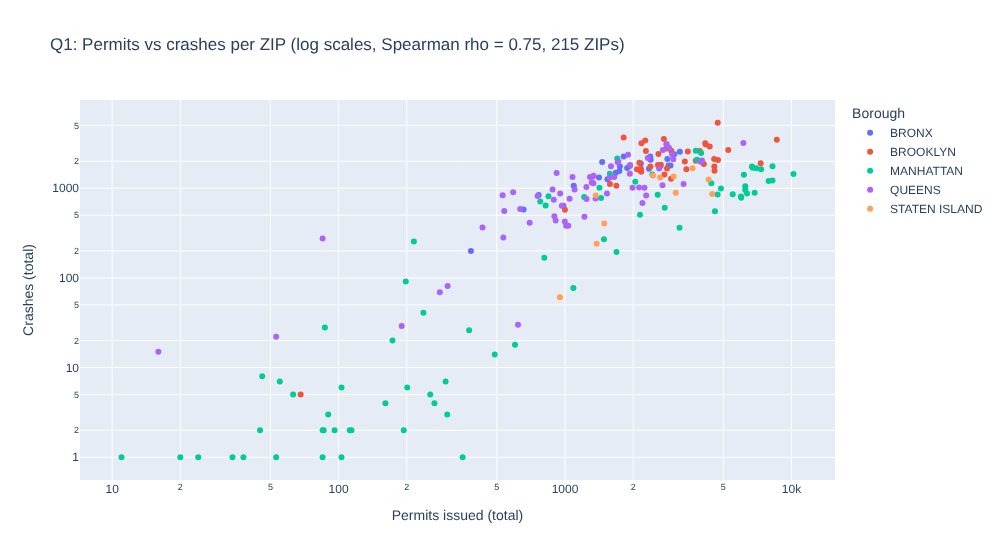

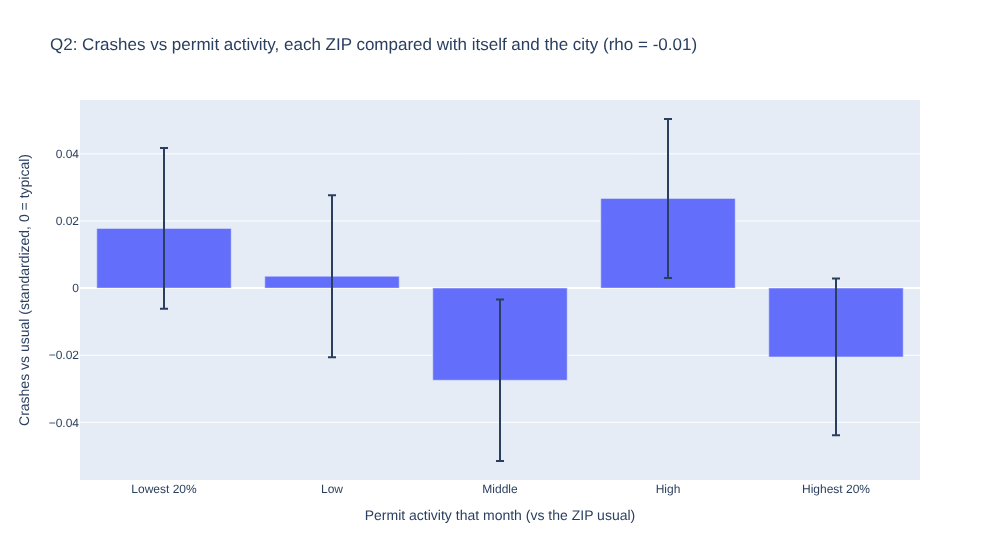

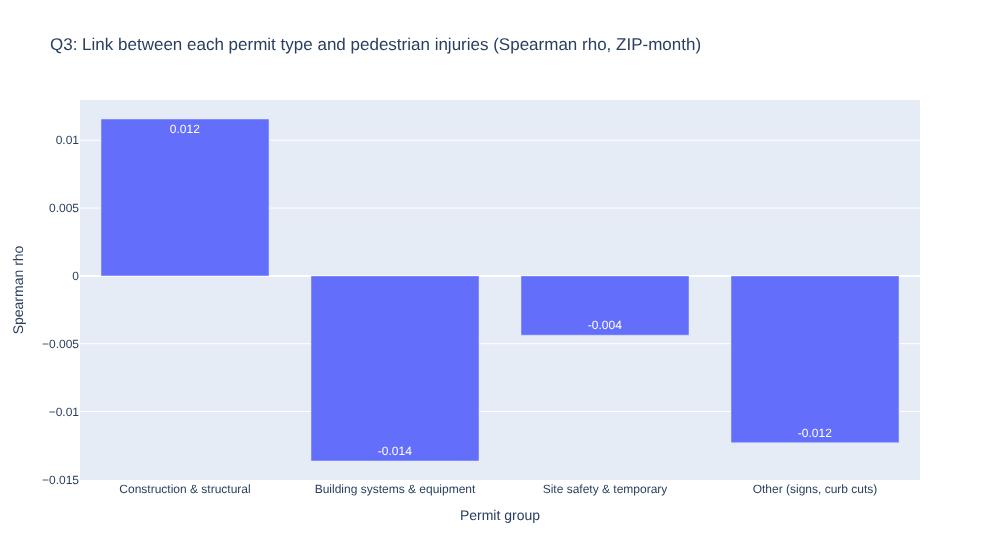

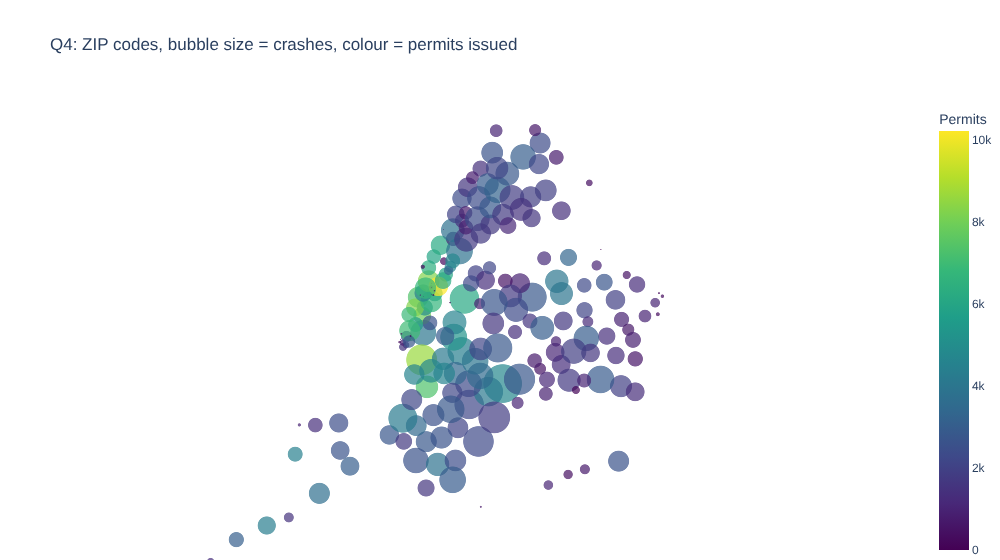

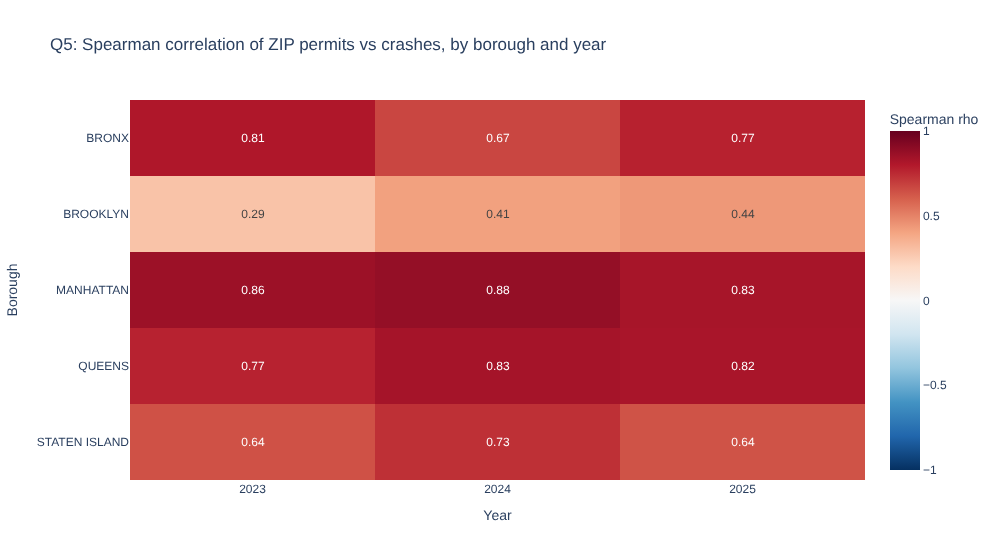

Q1: Permits vs crashes per ZIP (log scales, Spearman rho = 0.75, 215 ZIPs)
Q2: Crashes vs permit activity, each ZIP compared with itself and the city (rho = -0.01)
Q2 bar heights: [np.float64(0.018), np.float64(0.004), np.float64(-0.027), np.float64(0.027), np.float64(-0.021)]
Q3: {'Construction & structural': np.float64(0.012), 'Building systems & equipment': np.float64(-0.014), 'Site safety & temporary': np.float64(-0.004), 'Other (signs, curb cuts)': np.float64(-0.012)}
Q4 ZIPs plotted: 229
Q5 table:
                2023  2024  2025
BRONX          0.81  0.67  0.77
BROOKLYN       0.29  0.41  0.44
MANHATTAN      0.86  0.88  0.83
QUEENS         0.77  0.83  0.82
STATEN ISLAND  0.64  0.73  0.64


In [ ]:
import numpy as np
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go
import shutil

# --- Only needed if Colab restarted (also reload hc and tc from their CSVs) ---
# m = pd.read_csv('/content/integrated_clean.csv', dtype={'zip_code': str}, parse_dates=['year_month'])

# --- ZIP centroids for the map (median of all permit and crash coordinates in each ZIP) ---
coords = pd.concat([hc[['zip_code', 'latitude', 'longitude']],
                    tc[['zip_code', 'latitude', 'longitude']]]).dropna()
zip_centroids = coords.groupby('zip_code')[['latitude', 'longitude']].median().reset_index()
m = m.drop(columns=[c for c in ['latitude', 'longitude'] if c in m.columns])
m = m.merge(zip_centroids, on='zip_code', how='left')
assert len(m) == 8280, 'row count changed'
print('ZIPs without a centroid:', m.loc[m['latitude'].isna(), 'zip_code'].nunique())
m.to_csv('/content/integrated_clean.csv', index=False)
shutil.copy('/content/integrated_clean.csv', '/content/drive/MyDrive/DEV_Project/integrated_clean.csv')

def empty_fig(msg):
    """Placeholder chart when a filter leaves too little data."""
    fig = go.Figure()
    fig.update_layout(title=msg, xaxis={'visible': False}, yaxis={'visible': False})
    return fig

def adjusted(df, col):
    """Standardize `col` within each ZIP (z-score), then subtract the city-wide average for that month.
    Positive = busier than this ZIP's usual AND busier than the city trend that month."""
    g = df.groupby('zip_code')[col]
    std = g.transform('std').replace(0, np.nan)          # ZIPs with no variation have no z-score
    z = (df[col] - g.transform('mean')) / std
    return z - z.groupby(df['year_month']).transform('mean')

BOROUGH_ORDER = ['BRONX', 'BROOKLYN', 'MANHATTAN', 'QUEENS', 'STATEN ISLAND']

# ---------------- Q1: permits vs crashes per ZIP (3-year totals) ----------------
def fig_q1(df):
    zt = df.groupby(['zip_code', 'borough'], as_index=False)[['permits', 'crashes']].sum()
    zt = zt[(zt['permits'] > 0) & (zt['crashes'] > 0)]
    if len(zt) < 5:
        return empty_fig('Not enough ZIP codes for this filter')
    rho = zt['permits'].corr(zt['crashes'], method='spearman')
    return px.scatter(zt, x='permits', y='crashes', color='borough', hover_name='zip_code',
                      log_x=True, log_y=True, category_orders={'borough': BOROUGH_ORDER},
                      title=f'Q1: Permits vs crashes per ZIP (log scales, Spearman rho = {rho:.2f}, {len(zt)} ZIPs)',
                      labels={'permits': 'Permits issued (total)', 'crashes': 'Crashes (total)', 'borough': 'Borough'})

# ---------------- Q2: busier-than-usual permit months vs crashes ----------------
def fig_q2(df):
    d = df.copy()
    d['permits_adj'] = adjusted(d, 'permits')
    d['crashes_adj'] = adjusted(d, 'crashes')
    d = d.dropna(subset=['permits_adj', 'crashes_adj'])
    if len(d) < 50:
        return empty_fig('Not enough data for this filter')
    rho = d['permits_adj'].corr(d['crashes_adj'], method='spearman')
    labels = ['Lowest 20%', 'Low', 'Middle', 'High', 'Highest 20%']
    d['permit_level'] = pd.qcut(d['permits_adj'].rank(method='first'), 5, labels=labels)  # rank avoids tie errors
    s = d.groupby('permit_level', observed=True)['crashes_adj'].agg(['mean', 'sem']).reset_index()
    return px.bar(s, x='permit_level', y='mean', error_y='sem',
                  title=f'Q2: Crashes vs permit activity, each ZIP compared with itself and the city (rho = {rho:.2f})',
                  labels={'permit_level': 'Permit activity that month (vs the ZIP usual)',
                          'mean': 'Crashes vs usual (standardized, 0 = typical)'})

# ---------------- Q3: which permit group moves with pedestrian injuries ----------------
def fig_q3(df):
    groups = {'permits_construction': 'Construction & structural',
              'permits_systems': 'Building systems & equipment',
              'permits_site_safety': 'Site safety & temporary',
              'permits_other': 'Other (signs, curb cuts)'}
    y = adjusted(df, 'pedestrians_injured')
    rows = [{'permit group': label, 'rho': adjusted(df, col).corr(y, method='spearman')}
            for col, label in groups.items()]
    r = pd.DataFrame(rows).dropna()
    if r.empty:
        return empty_fig('Not enough data for this filter')
    return px.bar(r, x='permit group', y='rho', text_auto='.3f',
                  title='Q3: Link between each permit type and pedestrian injuries (Spearman rho, ZIP-month)',
                  labels={'rho': 'Spearman rho', 'permit group': 'Permit group'})

# ---------------- Q4: map, permits (colour) and crashes (size) per ZIP ----------------
def fig_q4(df):
    z = df.groupby('zip_code').agg(permits=('permits', 'sum'), crashes=('crashes', 'sum'),
                                   latitude=('latitude', 'first'), longitude=('longitude', 'first'),
                                   borough=('borough', 'first')).reset_index()
    z = z.dropna(subset=['latitude', 'longitude'])
    z = z[(z['permits'] + z['crashes']) > 0]
    if z.empty:
        return empty_fig('No ZIP codes for this filter')
    kwargs = dict(lat='latitude', lon='longitude', size='crashes', color='permits', hover_name='zip_code',
                  hover_data={'borough': True, 'permits': True, 'crashes': True, 'latitude': False, 'longitude': False},
                  size_max=28, zoom=9.2, center={'lat': 40.72, 'lon': -73.95},
                  color_continuous_scale='Viridis',
                  title='Q4: ZIP codes, bubble size = crashes, colour = permits issued',
                  labels={'permits': 'Permits', 'crashes': 'Crashes'})
    if hasattr(px, 'scatter_map'):
        fig = px.scatter_map(z, map_style='carto-positron', **kwargs)    # free tiles, no token needed
    else:
        fig = px.scatter_mapbox(z, mapbox_style='carto-positron', **kwargs)
    fig.update_layout(margin={'l': 0, 'r': 0, 'b': 0})
    return fig

def top_zips(df, n=8):
    z = df.groupby(['zip_code', 'borough'], as_index=False)[['permits', 'crashes']].sum()
    return z.nlargest(n, 'permits'), z.nlargest(n, 'crashes')

f4 = fig_q4(m)
by_permits, by_crashes = top_zips(m)
print('Top ZIPs by permits:\n', by_permits.to_string(index=False))
print('\nTop ZIPs by crashes:\n', by_crashes.to_string(index=False))

# ---------------- Q5: permits-crashes link by borough and year ----------------
def fig_q5(df):
    zy = df.groupby(['borough', 'zip_code', 'year'], as_index=False)[['permits', 'crashes']].sum()
    rows = []
    for (b, yr), g in zy.groupby(['borough', 'year']):
        if len(g) >= 8 and g['permits'].nunique() > 1 and g['crashes'].nunique() > 1:
            rows.append({'borough': b, 'year': int(yr), 'rho': g['permits'].corr(g['crashes'], method='spearman')})
    if not rows:
        return empty_fig('Not enough ZIP codes per borough for this filter')
    r = pd.DataFrame(rows).pivot(index='borough', columns='year', values='rho')
    fig = px.imshow(r, text_auto='.2f', color_continuous_scale='RdBu_r', zmin=-1, zmax=1, aspect='auto',
                    title='Q5: Spearman correlation of ZIP permits vs crashes, by borough and year',
                    labels={'color': 'Spearman rho', 'x': 'Year', 'y': 'Borough'})
    fig.update_xaxes(type='category')
    return fig

# ---------------- Run all five; titles carry the key statistics ----------------
f1, f2, f3, f4, f5 = fig_q1(m), fig_q2(m), fig_q3(m), fig_q4(m), fig_q5(m)
for f in (f1, f2, f3, f4, f5):
    f.show()
print(f1.layout.title.text)
print(f2.layout.title.text)
print('Q2 bar heights:', [round(v, 3) for v in f2.data[0].y])
print('Q3:', {x: round(v, 3) for x, v in zip(f3.data[0].x, f3.data[0].y)})
print('Q4 ZIPs plotted:', len(f4.data[0].lat))
print('Q5 table:\n', pd.DataFrame(f5.data[0].z, index=f5.data[0].y, columns=f5.data[0].x).round(2))

### 7.4 Chart functions (Q6-Q10)

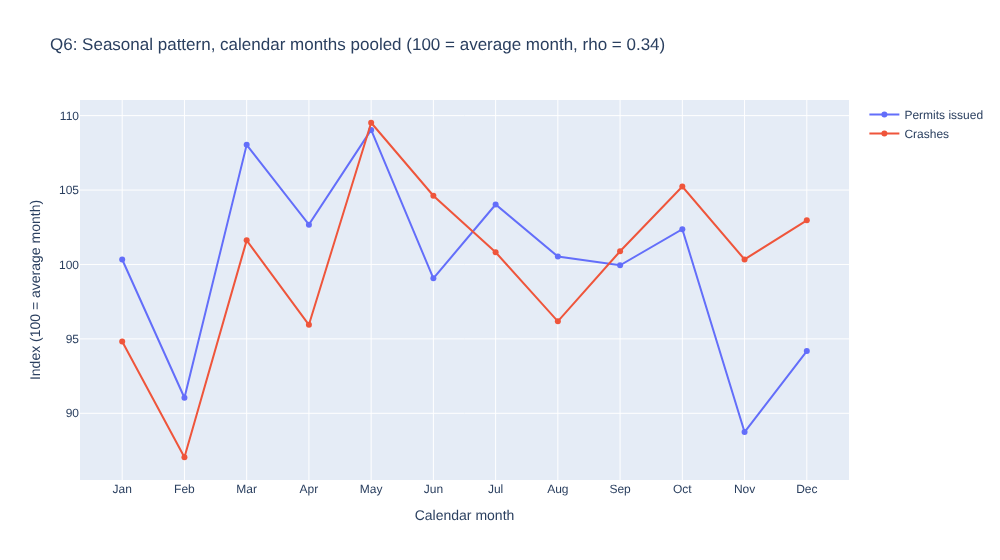

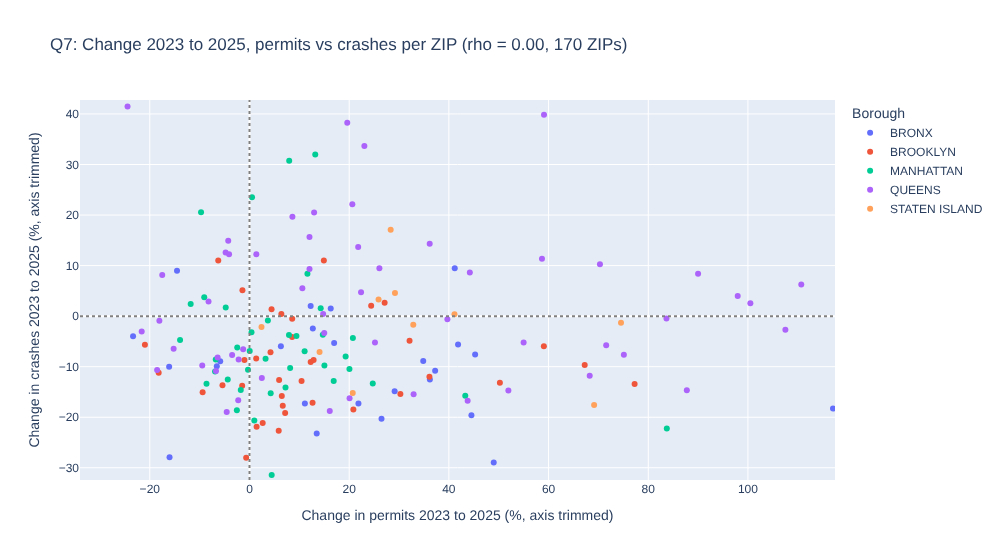

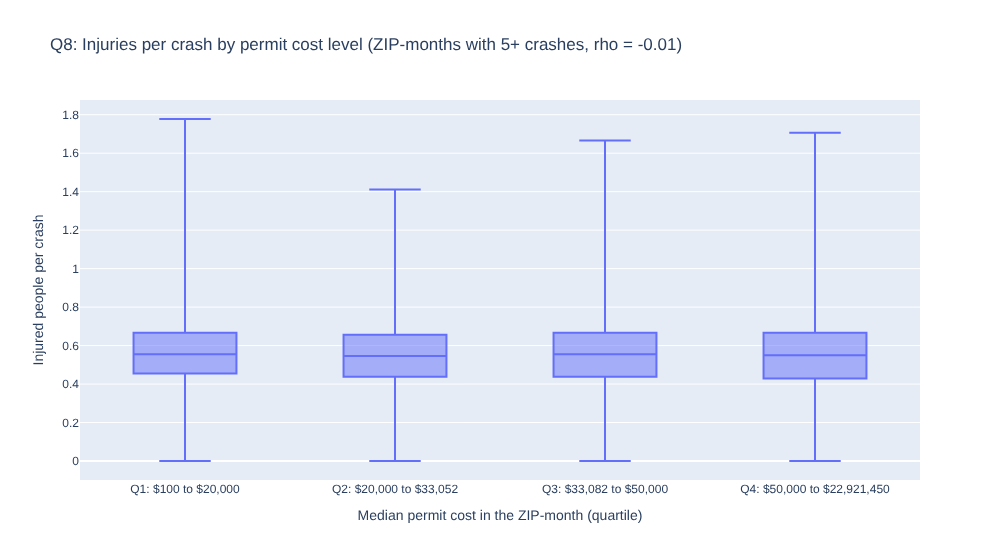

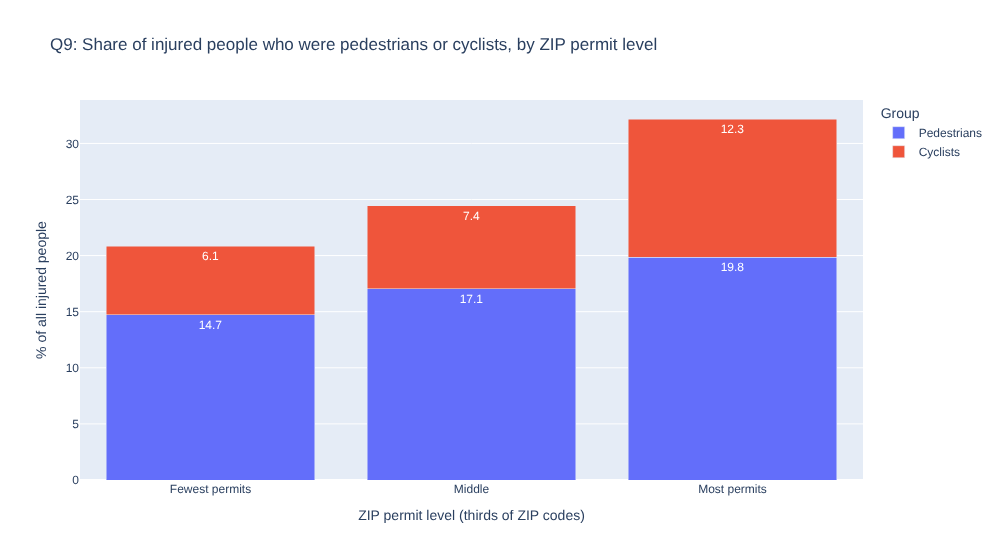

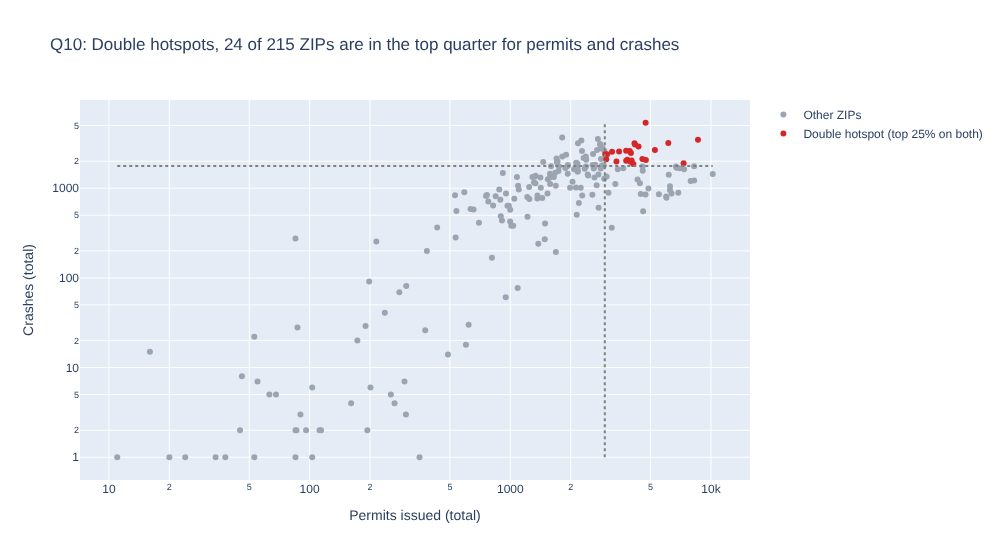

Q6: Seasonal pattern, calendar months pooled (100 = average month, rho = 0.34)
Q7: Change 2023 to 2025, permits vs crashes per ZIP (rho = 0.00, 170 ZIPs)
Q8: Injuries per crash by permit cost level (ZIP-months with 5+ crashes, rho = -0.01)
Q10: Double hotspots, 24 of 215 ZIPs are in the top quarter for permits and crashes
Q6 Permits issued [100, 91, 108, 103, 109, 99, 104, 101, 100, 102, 89, 94]
Q6 Crashes [95, 87, 102, 96, 110, 105, 101, 96, 101, 105, 100, 103]
Q7 ZIPs:  170 | median permit change %: 12.0 | median crash change %: -6.3
Q8 median injuries per crash by cost quartile:
 cost_group
Q1: $100 to $20,000           0.556
Q2: $20,000 to $33,052        0.545
Q3: $33,082 to $50,000        0.556
Q4: $50,000 to $22,921,450    0.550
Name: injuries_per_crash, dtype: float64
Q9 table:
        tercile  zips  Pedestrians  Cyclists
Fewest permits    70         14.7       6.1
        Middle    69         17.1       7.4
  Most permits    70         19.8      12.3
Q10 cutoffs: permits >= 295

In [ ]:
import numpy as np
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go

MONTH_NAMES = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']

# ---------------- Q6: seasonal rhythm ----------------
def fig_q6(df):
    g = df.groupby('month')[['permits', 'crashes']].sum()
    if len(g) < 3 or (g.mean() == 0).any():
        return empty_fig('Not enough data for this filter')
    idx = (g / g.mean() * 100).reset_index()                  # 100 = an average month
    rho = idx['permits'].corr(idx['crashes'], method='spearman')
    long = idx.melt(id_vars='month', value_vars=['permits', 'crashes'],
                    var_name='measure', value_name='monthly_index')
    long['measure'] = long['measure'].map({'permits': 'Permits issued', 'crashes': 'Crashes'})
    fig = px.line(long, x='month', y='monthly_index', color='measure', markers=True,
                  title=f'Q6: Seasonal pattern, calendar months pooled (100 = average month, rho = {rho:.2f})',
                  labels={'month': 'Calendar month', 'monthly_index': 'Index (100 = average month)', 'measure': ''})
    fig.update_xaxes(tickmode='array', tickvals=list(range(1, 13)), ticktext=MONTH_NAMES)
    return fig

# ---------------- Q7: change over time, permits vs crashes ----------------
def q7_data(df):
    if df.empty:
        return None, None, None
    y0, y1 = int(df['year'].min()), int(df['year'].max())
    if y0 == y1:
        return None, y0, y1
    a = df[df['year'] == y0].groupby(['zip_code', 'borough'])[['permits', 'crashes']].sum()
    b = df[df['year'] == y1].groupby(['zip_code', 'borough'])[['permits', 'crashes']].sum()
    z = a.join(b, lsuffix='_first', rsuffix='_last', how='inner').reset_index()
    z = z[(z['permits_first'] >= 50) & (z['crashes_first'] >= 50)].copy()   # avoid noisy % from tiny bases
    z['permit_change'] = (z['permits_last'] / z['permits_first'] - 1) * 100
    z['crash_change'] = (z['crashes_last'] / z['crashes_first'] - 1) * 100
    return z, y0, y1

def fig_q7(df):
    z, y0, y1 = q7_data(df)
    if z is None:
        return empty_fig('Needs data from at least two different years for this filter')
    if len(z) < 10:
        return empty_fig('Not enough ZIP codes for this filter')
    rho = z['permit_change'].corr(z['crash_change'], method='spearman')
    fig = px.scatter(z, x='permit_change', y='crash_change', color='borough', hover_name='zip_code',
                     category_orders={'borough': BOROUGH_ORDER},
                     title=f'Q7: Change {y0} to {y1}, permits vs crashes per ZIP (rho = {rho:.2f}, {len(z)} ZIPs)',
                     labels={'permit_change': f'Change in permits {y0} to {y1} (%, axis trimmed)',
                             'crash_change': f'Change in crashes {y0} to {y1} (%, axis trimmed)',
                             'borough': 'Borough'})
    fig.add_hline(y=0, line_dash='dot', line_color='gray')
    fig.add_vline(x=0, line_dash='dot', line_color='gray')
    for axis, col in (('x', 'permit_change'), ('y', 'crash_change')):   # trim axes to 2nd-98th percentile
        lo, hi = z[col].quantile([0.02, 0.98])
        pad = (hi - lo) * 0.1
        getattr(fig, f'update_{axis}axes')(range=[lo - pad, hi + pad])
    return fig

# ---------------- Q8: injuries per crash by permit cost level ----------------
def q8_data(df):
    d = df[(df['permits'] > 0) & df['median_cost'].notna() & (df['crashes'] >= 5)].copy()  # 5+ crashes: stable ratio
    if len(d) < 100:
        return None
    d['injuries_per_crash'] = d['persons_injured'] / d['crashes']
    d['q'] = pd.qcut(d['median_cost'].rank(method='first'), 4, labels=False)  # rank avoids tie errors
    bounds = d.groupby('q')['median_cost'].agg(['min', 'max'])
    names = {i: f"Q{i + 1}: ${r['min']:,.0f} to ${r['max']:,.0f}" for i, r in bounds.iterrows()}
    d['cost_group'] = d['q'].map(names)
    return d, [names[i] for i in sorted(names)]

def fig_q8(df):
    res = q8_data(df)
    if res is None:
        return empty_fig('Not enough ZIP-months for this filter')
    d, order = res
    rho = d['median_cost'].corr(d['injuries_per_crash'], method='spearman')
    return px.box(d, x='cost_group', y='injuries_per_crash', points=False,
                  category_orders={'cost_group': order},
                  title=f'Q8: Injuries per crash by permit cost level (ZIP-months with 5+ crashes, rho = {rho:.2f})',
                  labels={'cost_group': 'Median permit cost in the ZIP-month (quartile)',
                          'injuries_per_crash': 'Injured people per crash'})

# ---------------- Q9: pedestrian and cyclist share of injuries by ZIP permit level ----------------
def q9_table(df):
    z = df.groupby('zip_code', as_index=False)[['permits', 'persons_injured',
                                                'pedestrians_injured', 'cyclists_injured']].sum()
    z = z[z['persons_injured'] > 0].copy()
    if len(z) < 9:
        return None
    z['tercile'] = pd.qcut(z['permits'].rank(method='first'), 3,
                           labels=['Fewest permits', 'Middle', 'Most permits'])
    s = (z.groupby('tercile', observed=True)
           .agg(zips=('zip_code', 'size'), ped=('pedestrians_injured', 'sum'),
                cyc=('cyclists_injured', 'sum'), total=('persons_injured', 'sum'))
           .reset_index())
    s['Pedestrians'] = s['ped'] / s['total'] * 100       # pooled share, so big ZIPs count more
    s['Cyclists'] = s['cyc'] / s['total'] * 100
    return s

def fig_q9(df):
    s = q9_table(df)
    if s is None:
        return empty_fig('Not enough ZIP codes for this filter')
    long = s.melt(id_vars=['tercile', 'zips'], value_vars=['Pedestrians', 'Cyclists'],
                  var_name='group', value_name='share')
    return px.bar(long, x='tercile', y='share', color='group', barmode='stack', text_auto='.1f',
                  hover_data={'zips': True},
                  title='Q9: Share of injured people who were pedestrians or cyclists, by ZIP permit level',
                  labels={'tercile': 'ZIP permit level (thirds of ZIP codes)',
                          'share': '% of all injured people', 'group': 'Group', 'zips': 'ZIPs'})

# ---------------- Q10: double hotspots ----------------
def double_hotspots(df):
    z = df.groupby(['zip_code', 'borough'], as_index=False)[['permits', 'crashes']].sum()
    z = z[(z['permits'] > 0) & (z['crashes'] > 0)].copy()
    if len(z) < 8:
        return None, None, None
    qx, qy = z['permits'].quantile(0.75), z['crashes'].quantile(0.75)
    z['group'] = np.where((z['permits'] >= qx) & (z['crashes'] >= qy),
                          'Double hotspot (top 25% on both)', 'Other ZIPs')
    return z, qx, qy

def fig_q10(df):
    z, qx, qy = double_hotspots(df)
    if z is None:
        return empty_fig('Not enough ZIP codes for this filter')
    n_hot = int((z['group'] != 'Other ZIPs').sum())
    fig = px.scatter(z, x='permits', y='crashes', color='group', hover_name='zip_code',
                     hover_data={'borough': True}, log_x=True, log_y=True,
                     color_discrete_map={'Double hotspot (top 25% on both)': '#d62728', 'Other ZIPs': '#9aa5b1'},
                     title=f'Q10: Double hotspots, {n_hot} of {len(z)} ZIPs are in the top quarter for permits and crashes',
                     labels={'permits': 'Permits issued (total)', 'crashes': 'Crashes (total)', 'group': ''})
    # quartile guide lines drawn as traces so they work on log axes
    fig.add_trace(go.Scatter(x=[qx, qx], y=[z['crashes'].min(), z['crashes'].max()], mode='lines',
                             line=dict(dash='dot', color='gray'), showlegend=False, hoverinfo='skip'))
    fig.add_trace(go.Scatter(x=[z['permits'].min(), z['permits'].max()], y=[qy, qy], mode='lines',
                             line=dict(dash='dot', color='gray'), showlegend=False, hoverinfo='skip'))
    return fig

# ---------------- Run and print the key numbers ----------------
f6, f7, f8, f9, f10 = fig_q6(m), fig_q7(m), fig_q8(m), fig_q9(m), fig_q10(m)
for f in (f6, f7, f8, f9, f10):
    f.show()

for f in (f6, f7, f8, f10):
    print(f.layout.title.text)
for tr in f6.data:
    print('Q6', tr.name, [round(v) for v in tr.y])
z7, y0, y1 = q7_data(m)
print('Q7 ZIPs: ', len(z7), '| median permit change %:', round(z7['permit_change'].median(), 1),
      '| median crash change %:', round(z7['crash_change'].median(), 1))
d8, order8 = q8_data(m)
print('Q8 median injuries per crash by cost quartile:\n',
      d8.groupby('cost_group')['injuries_per_crash'].median().round(3).reindex(order8))
print('Q9 table:\n', q9_table(m)[['tercile', 'zips', 'Pedestrians', 'Cyclists']].round(1).to_string(index=False))
hot, qx, qy = double_hotspots(m)
hot_only = hot[hot['group'] != 'Other ZIPs']
print('Q10 cutoffs: permits >=', round(qx), '| crashes >=', round(qy))
print('Q10 hotspot ZIPs by borough:', hot_only['borough'].value_counts().to_dict())
print('Q10 top hotspots:\n', hot_only.sort_values('crashes', ascending=False).head(8)[['zip_code', 'borough', 'permits', 'crashes']].to_string(index=False))

### 7.5 Findings
**Q1.** Across the 215 ZIPs with at least one permit and one crash (ZIPs with none in three years are left out, since log scales cannot show zero), total permits and total crashes are strongly related (Spearman rho = 0.75). This mostly reflects ZIP size and activity: busy ZIPs have more of everything. Q1 is a baseline, not evidence that permits matter.

**Q2.** Once each ZIP is compared with its own usual level and the city trend that month, permit activity and crashes show no detectable link (rho = -0.01). The bars do not rise or fall steadily across permit levels, and most error bars cross zero.

**Q3.** None of the four permit groups moves with pedestrian injuries (rho between -0.014 and +0.012). With roughly 8,000 ZIP-months, values within about +-0.02 cannot be told apart from zero. Pedestrian injuries are also small counts (about 0.1 per crash), which makes the data noisy.

**Q4.** The map shows two different geographies. Permits are highest in Manhattan (top ZIPs by permits: 10022 with 10,206, then Brooklyn's 11201 with 8,614, and Manhattan's 10011, 10019 and 10003), while crashes are highest in Brooklyn and Queens (11207 with 5,374 crashes, then 11236, 11208, 11201 and 11234). Manhattan holds 36.8% of all permits but 17.7% of crashes; Brooklyn holds 26.4% and 33.8%, Queens 20.5% and 28.7%. Only one ZIP, 11201 (downtown Brooklyn), is in both top-8 lists. This fits Q5, where Brooklyn has the weakest permits-crashes link. (The image saved in this notebook has no street background; running the cell draws the street map.)

**Q5.** The ZIP-level link between permits and crashes holds in every borough and year, but its strength differs: Manhattan 0.83-0.88, Queens 0.77-0.83, Bronx 0.67-0.81, Staten Island 0.64-0.73, and Brooklyn clearly lower at 0.29-0.44. The pattern is stable across 2023-2025. We do not explain why Brooklyn differs, because the data cannot tell us.

**Q6.** Permits and crashes share only a weak seasonal pattern (rho = 0.34 across 12 calendar months, too few points to call it reliable). Both are highest in May (index 109 for permits, 110 for crashes, where 100 is an average month). Permits then dip in November (89) and February (91), while crashes dip in February (87) and are high again in October (105) and December (103). All months stay between 87 and 110.

**Q7.** Across the 170 ZIPs with at least 50 permits and 50 crashes in 2023, how much a ZIP's permits changed from 2023 to 2025 is unrelated to how much its crashes changed (rho = 0.00). The typical ZIP had 12.0% more permits and 6.3% fewer crashes. Because 2023 crashes are undercounted more than 2025 (section 7.2), the true fall in crashes may be larger.

**Q8.** Injuries per crash are almost identical across the four permit-cost quartiles (median 0.545 to 0.556 injured people per crash; rho = -0.01 over ZIP-months with 5 or more crashes). Costlier permit activity does not go with more severe crashes.

**Q9.** The share of injured people who were pedestrians or cyclists rises with ZIP permit level: pedestrians 14.7%, 17.1%, 19.8% and cyclists 6.1%, 7.4%, 12.3% from the third of ZIPs with the fewest permits to the third with the most. This does not show that permits cause it. Manhattan has the highest shares overall (23.9% pedestrians, 20.5% cyclists), and Manhattan and Brooklyn ZIPs make up 49 of the 70 ZIPs in the most-permits third, so the pattern probably reflects borough and street type.

**Q10.** 24 of 215 ZIPs are in the top quarter for both permits (2,958 or more) and crashes (1,770 or more). If the two were unrelated we would expect about 13, so the overlap is real. The double hotspots are concentrated: Brooklyn 14, Queens 5, Manhattan 3, Bronx 2, Staten Island none. The largest are 11207 (Brooklyn; 4,723 permits, 5,374 crashes), 11201, 11101 (Queens), 11212 and 11220.

**Overall.** Places with more permit activity have more crashes (Q1, Q5), but this mostly reflects ZIP size and borough, because permits concentrate in Manhattan and crashes in Brooklyn and Queens (Q4). Month to month and from 2023 to 2025, a ZIP's permit surges do not line up with its crash surges (Q2, Q3, Q7), and crash severity does not differ by permit cost (Q8). Pedestrian and cyclist shares are higher in permit-heavy ZIPs (Q9), probably because of where those ZIPs are. About one in nine ZIPs is a double hotspot, mostly in Brooklyn (Q10). We report the null results plainly, and none of this is a causal claim.

## 8. Contributions
**Team:** 5 members (see the team IDs in the submission email).

| Member | Contribution |
|---|---|
| Mina Ayman Andrawes (16003514) | Dataset selection and justification; loading with filtered sampling; EDA; pre-integration cleaning (including ZIP recovery and its validation); integration (ZIP x month); post-integration cleaning; research questions Q1-Q10 and their visualizations; website (filters, search, Generate Report, story section); deployment; README |
| Teammates 1-4 | No contribution received at the time of submission; they could not be reached.

**AI assistance:** Claude (Anthropic) was used for step-by-step guidance and for drafting code and text, which was then run, checked and adapted by the author. The prompts are listed in section 9.

## 9. Prompts Used
Typed prompts, in order, copied as written (spelling unchanged). Short confirmations ("go", "done", "next"), pasted outputs and screenshots are omitted.

1. "here's my data engineering and visualization project 1 files, project description and data catalog , please read the description thoroughly and provide step by step eli5 from download and setup to submission. provide a checklist and update it as we go and make sure to guide me with baby steps like where to click and most importantly make no mistakes. i want you to give me a quick summary of what will be doing at first efore starting"
2. "we have 5 on r team but i cant get hold of them and i tried reaching out in many ways so until they show up i will be working alone so create 3 day plan to cover all phases and deliverables"
3. "dont change the original plan  lets continue on the og plan i still have 24 hours"
4. "do i need to change the reasoning in section 1?"
5. "what do you mean row counts?"
6. "quick question while it runs why are some outputs like this "rbx6-tga4" are they hashed or smth"
7. "in crashes by borough whaat is the missing label mean?"
8. "can yo give me cell 6.1 as a whole updated"
9. "colab is not connecting"
10. "ok lets focus and lock in the submission is tonight t midnight: i need to finalize the notebook with you because i think its messy kind of then i we should continue the missing stuff from the notebook then lets see whats left"
11. "i need you to make your responses straight to the point and concise from now on"
12. "dont start any execution unless i tell you please"
13. "question first: do you have access to my colab and go there edit yourself then give me a list of things you changed?"
14. "i will be using jupyter just to see what you did since colab is not working: 1. why did you add 10 dataset links arent they ony 2 2. which prompts did you use 3. who are the 8 contributions"
15. "i want a copy that runs on plain jupyter just to run then upload notebook with outputs if thats okay?"
16. "list all notebook contents and if anything is missing?"
17. "slowlyy please in step 1: what should my folder contain"
18. "charts are empty"
19. "what repo folder do i run it at?"
20. "first before that, theres a payache folder that was created what is this"
21. "what does the project description documet say about this part"
22. "no card host"
23. "i switched to streamlit.io"
24. "ill go back to render and cancel plan later"
25. "can you provide the fial clean notebook"

### Structured prompts by project part
Condensed from the work done, one per part of the project. These are summaries of what was asked, not verbatim prompts.

1. **Project understanding and plan.** Context: DEV Project 1, NYC Open Data, team of 5, working solo for now. Task: read the project description and data catalog, summarize the requirements, and give a step-by-step plan with a checklist. Constraints: beginner-friendly, exact clicks, no mistakes, deadline 9 Nov midnight.
2. **Dataset selection.** Task: choose one housing and one transportation dataset from the catalog that share a bridge (ZIP, borough, date) and have at least 9 columns. Output: justification, the dataset IDs, and a combined research question.
3. **Loading with filtered sampling.** Task: load both datasets through the NYC Open Data API using a filtered sample, since the full data is too large. Constraints: justify the date window, download in pages, retry on 503 errors, and cache the files.
4. **Exploratory data analysis.** Task: describe both datasets with structure, missing values, duplicates, statistics and plots. Output: written findings, plus diagnostics to check suspicious patterns before cleaning.
5. **Pre-integration cleaning.** Task: clean each dataset: duplicates, inconsistent formats, placeholder values, and outliers. Constraints: explain every decision, never drop data silently, and use both a statistical rule and a domain rule for outliers.
6. **ZIP recovery and validation.** Task: recover the missing ZIP and borough values in the crash data from coordinates. Constraints: validate on held-out rows, report accuracy by distance, and check whether the dropped rows differ from the kept ones.
7. **Integration.** Task: integrate the datasets at an appropriate level. Constraints: no row-level join, explain why ZIP by month, choose and justify the join type, and verify that totals are preserved.
8. **Post-integration cleaning.** Task: clean the merged table: new missing values, redundant columns, data types, and non-NYC ZIPs. Constraints: set counts to 0 only where justified, leave undefined ratios blank, and add consistency checks.
9. **Research questions and charts.** Task: write 10 non-trivial research questions linking both datasets, one chart each. Constraints: avoid simple counts and causal claims, adjust for ZIP size and city-wide trends, and write honest findings including null results.
10. **Website, deployment and README.** Task: build a Dash website with multiple filters, a search box, a Generate Report button, a variety of charts and a story section. Then deploy it, push to GitHub, and write a README with setup steps and contributions.

## 10. Dataset Links
- Housing and Development: DOB NOW: Build, Approved Permits (`rbx6-tga4`): https://data.cityofnewyork.us/d/rbx6-tga4
- Transportation: Motor Vehicle Collisions, Crashes (`h9gi-nx95`): https://data.cityofnewyork.us/d/h9gi-nx95
- GitHub repository: https://github.com/minaandrawes/nyc-housing-transport-story
- Deployed website: https://nyc-housing-transport-story.onrender.com/